In [52]:
import tensorflow as tf
import numpy as np
import pandas as pd

In [53]:
# df = pd.read_csv("./data/data-01-test-score.csv", encoding = 'utf-8', dtype=np.float32)
data = np.loadtxt('./data/data-01-test-score.csv', delimiter=',', dtype=np.float32)
data

array([[ 73.,  80.,  75., 152.],
       [ 93.,  88.,  93., 185.],
       [ 89.,  91.,  90., 180.],
       [ 96.,  98., 100., 196.],
       [ 73.,  66.,  70., 142.],
       [ 53.,  46.,  55., 101.],
       [ 69.,  74.,  77., 149.],
       [ 47.,  56.,  60., 115.],
       [ 87.,  79.,  90., 175.],
       [ 79.,  70.,  88., 164.],
       [ 69.,  70.,  73., 141.],
       [ 70.,  65.,  74., 141.],
       [ 93.,  95.,  91., 184.],
       [ 79.,  80.,  73., 152.],
       [ 70.,  73.,  78., 148.],
       [ 93.,  89.,  96., 192.],
       [ 78.,  75.,  68., 147.],
       [ 81.,  90.,  93., 183.],
       [ 88.,  92.,  86., 177.],
       [ 78.,  83.,  77., 159.],
       [ 82.,  86.,  90., 177.],
       [ 86.,  82.,  89., 175.],
       [ 78.,  83.,  85., 175.],
       [ 76.,  83.,  71., 149.],
       [ 96.,  93.,  95., 192.]], dtype=float32)

In [54]:
x_data = data[:,:-1]
y_data = data[:,[-1]]

In [55]:
print(x_data, 'x_data shape:', x_data.shape)
print(y_data, 'y_data shape:', y_data.shape)

[[ 73.  80.  75.]
 [ 93.  88.  93.]
 [ 89.  91.  90.]
 [ 96.  98. 100.]
 [ 73.  66.  70.]
 [ 53.  46.  55.]
 [ 69.  74.  77.]
 [ 47.  56.  60.]
 [ 87.  79.  90.]
 [ 79.  70.  88.]
 [ 69.  70.  73.]
 [ 70.  65.  74.]
 [ 93.  95.  91.]
 [ 79.  80.  73.]
 [ 70.  73.  78.]
 [ 93.  89.  96.]
 [ 78.  75.  68.]
 [ 81.  90.  93.]
 [ 88.  92.  86.]
 [ 78.  83.  77.]
 [ 82.  86.  90.]
 [ 86.  82.  89.]
 [ 78.  83.  85.]
 [ 76.  83.  71.]
 [ 96.  93.  95.]] x_data shape: (25, 3)
[[152.]
 [185.]
 [180.]
 [196.]
 [142.]
 [101.]
 [149.]
 [115.]
 [175.]
 [164.]
 [141.]
 [141.]
 [184.]
 [152.]
 [148.]
 [192.]
 [147.]
 [183.]
 [177.]
 [159.]
 [177.]
 [175.]
 [175.]
 [149.]
 [192.]] y_data shape: (25, 1)


In [56]:
model = tf.keras.Sequential()

# 입력 레이어 추가 
model.add(tf.keras.Input(shape=(3,)))

# 출력 레이어 추가 -> activation 는 linear(선형 회기)
model.add(tf.keras.layers.Dense(units=1, activation='linear'))

# 데이터를 표준화 시켜서 0.1 사용가능 
# 표준화 시키지 않았다면 1e-5 정도 사용하면 된다
model.compile(
  optimizer = tf.keras.optimizers.SGD(learning_rate=0.000001), # 사용할 최적화 알고리즘 sgd:확률적 경사하강법
  loss = 'mse'  # 손실함수 
)

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4 (16.00 B)

 Trainable params: 4 (16.00 B)

 Non-trainable params: 0 (0.00 B)

In [57]:
start_weights = model.layers[0].get_weights()
print(f"학습전 : w {start_weights[0]}, b {start_weights[1]}")

학습전 : w [[1.0800897]
 [0.6349448]
 [0.7905141]], b [0.]


In [58]:
# 4. fit 메소드로 트레이닝
# 학습 
loss =  model.fit(x_data, y_data, epochs=200)

Epoch 1/200


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 1503.4319
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 1388.9943
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 1283.3527
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 1185.8302
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 1095.8015
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 1012.6920
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 935.9701
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 865.1443
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 799.7620
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 739.4039
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 683.6853
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 632.2488
Epoch 13/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 584.7643
Epoch 14/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 540.9299
Epoch 15/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 500

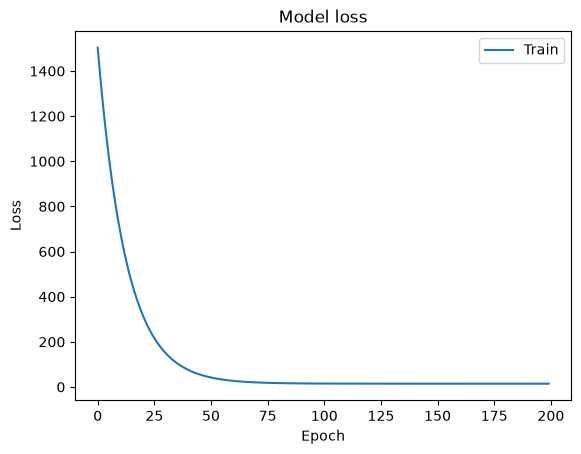

In [59]:
# loss 값의 시각화

import matplotlib.pyplot as plt

plt.plot(loss.history['loss'])
plt.title('Model loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train'], loc='upper right')
plt.show()

In [60]:
# 학습을 통해 구한 w1, w2, w3, bias 값
